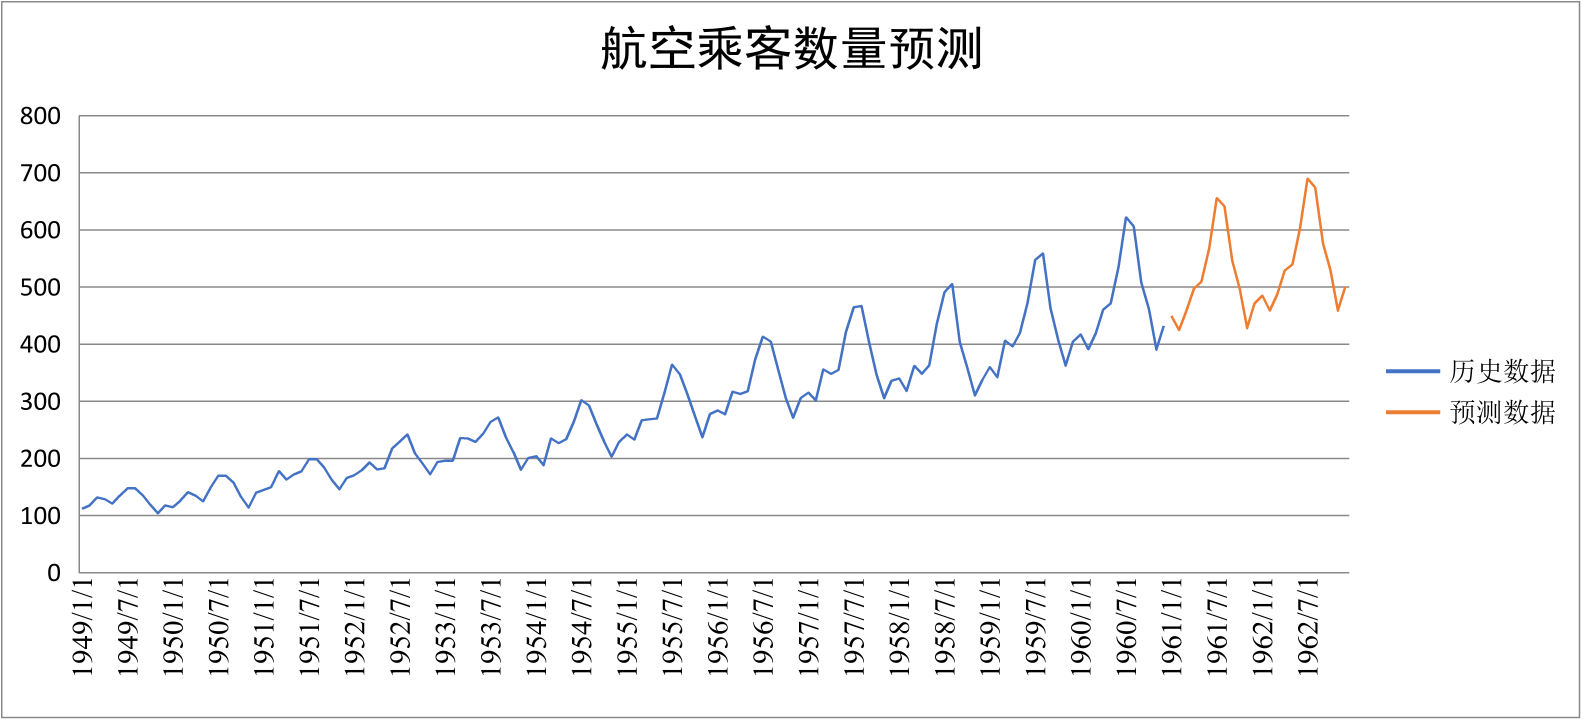

In [1]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display
import zipfile
from xml.etree import ElementTree as ET

FP=Path(r'C:\Windows\Fonts'); RS=getattr(Image,'Resampling',Image)
BASE=Path(r'C:\Users\28349\Desktop\上学期\商业数据分析\20260830 CDA教材资料2025\20260830 CDA教材资料2025\1《CDA 一级认证教材：商业数据分析》\第10章 使用效应分解方法做预报')
N='{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'

def RD(p,sh):
    z=zipfile.ZipFile(p)
    ss=[''.join(t.text or '' for t in s.iter(N+'t')) for s in ET.fromstring(z.read('xl/sharedStrings.xml'))] if 'xl/sharedStrings.xml' in z.namelist() else []
    o={}
    for c in ET.fromstring(z.read('xl/worksheets/sheet%d.xml'%sh)).iter(N+'c'):
        v=c.find(N+'v')
        if v is not None: o[c.get('r')]=ss[int(v.text)] if c.get('t')=='s' else float(v.text)
    return o

S=4
def NEW(W,H):
    im=Image.new('RGB',(W*S,H*S),'white'); return im,ImageDraw.Draw(im)
def END(im,W,H): return im.resize((W,H),RS.BOX)
def GLYP(t,z,fn,c):
    f=ImageFont.truetype(str(FP/fn),max(1,int(round(z*S))))
    tmp=Image.new('RGBA',(int((len(t)*z*1.6+100)*S),int((z*2.4+40)*S)),(0,0,0,0))
    ImageDraw.Draw(tmp).text((12*S,8*S),t,font=f,fill=(*c,255))
    return tmp.crop(tmp.getbbox())
def T(im,t,x,y,z,fn='simsun.ttc',c=(0,0,0),an='lt',rot=0):
    g=GLYP(t,z,fn,c)
    if rot: g=g.rotate(rot,expand=True,resample=RS.BICUBIC)
    w,h=g.size
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(g,(int(round(x*S-ax)),int(round(y*S-ay))),g)
def TR(im,parts,x,y,z,an='mt'):
    gs=[GLYP(t,z,fn,c) for t,fn,c in parts]
    h=max(g.height for g in gs); w=sum(g.width for g in gs)
    row=Image.new('RGBA',(w,h),(0,0,0,0)); xx=0
    for g in gs: row.paste(g,(xx,(h-g.height)//2),g); xx+=g.width
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(row,(int(round(x*S-ax)),int(round(y*S-ay))),row)
def HL(d,x0,x1,y,c,w=1): d.line([(int(x0*S),int(y*S)),(int(x1*S),int(y*S))],fill=c,width=max(1,int(round(w*S))))
def VL(d,x,y0,y1,c,w=1): d.line([(int(x*S),int(y0*S)),(int(x*S),int(y1*S))],fill=c,width=max(1,int(round(w*S))))
def LN(d,pts,c,w=2): d.line([(int(round(x*S)),int(round(y*S))) for x,y in pts],fill=c,width=max(1,int(round(w*S))),joint='curve')
def RC(d,x0,y0,x1,y1,c,w=1): d.rectangle((int(x0*S),int(y0*S),int(x1*S),int(y1*S)),outline=c,width=max(1,int(round(w*S))))
def DOT(d,x,y,r,c,w=1.5): d.ellipse((int((x-r)*S),int((y-r)*S),int((x+r)*S),int((y+r)*S)),fill=(255,255,255),outline=c,width=max(1,int(round(w*S))))

P1=BASE/'AIR_WPS自带AI功能做时间序列预测.xlsx'
if not P1.exists(): P1=Path('AIR_WPS自带AI功能做时间序列预测.xlsx')
D1=RD(P1,2); HIS1=[D1['B%d'%i] for i in range(2,146)]; PRE1=[D1['C%d'%i] for i in range(146,170)]
G=(137,137,137); BL1=(68,114,196); BL2=(91,155,213); OR=(237,125,49)
BL3=(69,139,250); GR=(64,182,140); GL=(224,230,241); GL2=(234,238,245)
def chart1():
    W,H=1582,720; im,d=NEW(W,H)
    yv=lambda v:572.6-v/800*457.1
    X=lambda i:82+i*7.565
    for v in range(0,801,100): HL(d,79,1349,yv(v),G,1.5)
    VL(d,79,115.5,573,G,1.5)
    for v in range(0,801,100): T(im,str(v),60,yv(v),27,'calibri.ttf',an='rm')
    T(im,'航空乘客数量预测',W/2,25,48,'simhei.ttf',an='mt')
    LN(d,[(X(i),yv(v)) for i,v in enumerate(HIS1)],BL1,2.5)
    LN(d,[(X(i+144),yv(v)) for i,v in enumerate(PRE1)],OR,2.5)
    for i in range(0,168,6):
        T(im,'%d/%d/1'%(1949+i//12,1 if i%12==0 else 7),X(i),579,29,'times.ttf',an='mt',rot=90)
    HL(d,1386,1440,371,BL1,4); T(im,'历史数据',1450,371,27,an='lm')
    HL(d,1386,1440,412,OR,4); T(im,'预测数据',1450,412,27,an='lm')
    RC(d,1,1,W-2,H-2,G,1.5)
    return END(im,W,H)
out=chart1()
out.save('航空乘客数量预测.png')
display(out)


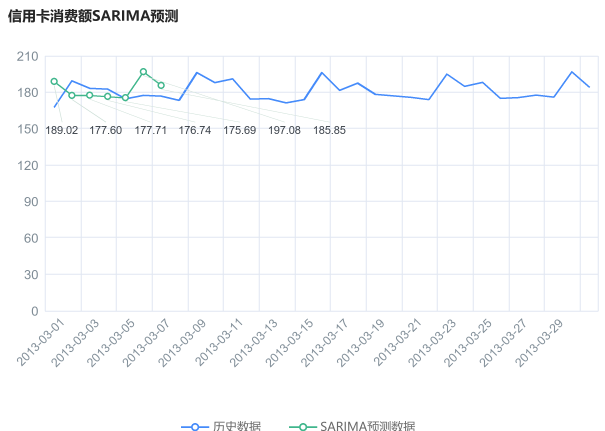

In [2]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display
import zipfile
from xml.etree import ElementTree as ET

FP=Path(r'C:\Windows\Fonts'); RS=getattr(Image,'Resampling',Image)
BASE=Path(r'C:\Users\28349\Desktop\上学期\商业数据分析\20260830 CDA教材资料2025\20260830 CDA教材资料2025\1《CDA 一级认证教材：商业数据分析》\第10章 使用效应分解方法做预报')
N='{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'

def RD(p,sh):
    z=zipfile.ZipFile(p)
    ss=[''.join(t.text or '' for t in s.iter(N+'t')) for s in ET.fromstring(z.read('xl/sharedStrings.xml'))] if 'xl/sharedStrings.xml' in z.namelist() else []
    o={}
    for c in ET.fromstring(z.read('xl/worksheets/sheet%d.xml'%sh)).iter(N+'c'):
        v=c.find(N+'v')
        if v is not None: o[c.get('r')]=ss[int(v.text)] if c.get('t')=='s' else float(v.text)
    return o

S=4
def NEW(W,H):
    im=Image.new('RGB',(W*S,H*S),'white'); return im,ImageDraw.Draw(im)
def END(im,W,H): return im.resize((W,H),RS.BOX)
def GLYP(t,z,fn,c):
    f=ImageFont.truetype(str(FP/fn),max(1,int(round(z*S))))
    tmp=Image.new('RGBA',(int((len(t)*z*1.6+100)*S),int((z*2.4+40)*S)),(0,0,0,0))
    ImageDraw.Draw(tmp).text((12*S,8*S),t,font=f,fill=(*c,255))
    return tmp.crop(tmp.getbbox())
def T(im,t,x,y,z,fn='simsun.ttc',c=(0,0,0),an='lt',rot=0):
    g=GLYP(t,z,fn,c)
    if rot: g=g.rotate(rot,expand=True,resample=RS.BICUBIC)
    w,h=g.size
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(g,(int(round(x*S-ax)),int(round(y*S-ay))),g)
def TR(im,parts,x,y,z,an='mt'):
    gs=[GLYP(t,z,fn,c) for t,fn,c in parts]
    h=max(g.height for g in gs); w=sum(g.width for g in gs)
    row=Image.new('RGBA',(w,h),(0,0,0,0)); xx=0
    for g in gs: row.paste(g,(xx,(h-g.height)//2),g); xx+=g.width
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(row,(int(round(x*S-ax)),int(round(y*S-ay))),row)
def HL(d,x0,x1,y,c,w=1): d.line([(int(x0*S),int(y*S)),(int(x1*S),int(y*S))],fill=c,width=max(1,int(round(w*S))))
def VL(d,x,y0,y1,c,w=1): d.line([(int(x*S),int(y0*S)),(int(x*S),int(y1*S))],fill=c,width=max(1,int(round(w*S))))
def LN(d,pts,c,w=2): d.line([(int(round(x*S)),int(round(y*S))) for x,y in pts],fill=c,width=max(1,int(round(w*S))),joint='curve')
def RC(d,x0,y0,x1,y1,c,w=1): d.rectangle((int(x0*S),int(y0*S),int(x1*S),int(y1*S)),outline=c,width=max(1,int(round(w*S))))
def DOT(d,x,y,r,c,w=1.5): d.ellipse((int((x-r)*S),int((y-r)*S),int((x+r)*S),int((y+r)*S)),fill=(255,255,255),outline=c,width=max(1,int(round(w*S))))

P2=BASE/'信用卡消费额_WPS自带AI功能做时间序列预测.xlsx'
if not P2.exists(): P2=Path('信用卡消费额_WPS自带AI功能做时间序列预测.xlsx')
D2=RD(P2,2); HIS2=[D2['B%d'%i] for i in range(2,33)]; PRE2=[D2['C%d'%i] for i in range(33,40)]
G=(137,137,137); BL1=(68,114,196); BL2=(91,155,213); OR=(237,125,49)
BL3=(69,139,250); GR=(64,182,140); GL=(224,230,241); GL2=(234,238,245)
def chart2():
    W,H=605,431; im,d=NEW(W,H)
    yv=lambda v:311-v/210*255
    X=lambda i:54+i*17.85
    for y in [56,92,128,165,201,237,274,311]: HL(d,45,598,y,GL,1)
    for x in [45,81,116,152,188,223,259,295,330,366,402,437,473,509,544,580,598]: VL(d,x,56,311,GL,1)
    for v in range(0,211,30): T(im,str(v),38,yv(v),13,'arial.ttf',(125,138,148),an='rm')
    T(im,'信用卡消费额SARIMA预测',8,9,14,'msyhbd.ttc',(37,37,37))
    LN(d,[(X(i),yv(v)) for i,v in enumerate(HIS2)],BL3,1.8)
    LN(d,[(X(i),yv(v)) for i,v in enumerate(PRE2)],GR,1.5)
    LX=[X(i) for i in range(7)]
    for _ in range(80):
        for i in range(6):
            g=LX[i+1]-LX[i]
            if g<45: p=(45-g)/2; LX[i]-=p; LX[i+1]+=p
        LX[0]=max(LX[0],62)
    for i,v in enumerate(PRE2):
        x,y=X(i),yv(v); DOT(d,x,y,3.5,GR,1.5)
        d.line([(int(x*S),int((y+4)*S)),(int(LX[i]*S),int(122*S))],fill=(210,226,219),width=max(1,int(round(.7*S))))
        T(im,'%.2f'%v,LX[i],130,11,'arial.ttf',(60,66,74),an='mm')
    for k in range(15):
        T(im,'2013-03-%02d'%(1+2*k),(X(2*k)+10),318,12,'arial.ttf',(125,138,148),an='rt',rot=45)
    for x,c,t in [(195,BL3,'历史数据'),(303,GR,'SARIMA预测数据')]:
        HL(d,x-14,x+14,427,c,1.8); DOT(d,x,427,4,c,1.8); T(im,t,x+18,427,12,'msyh.ttc',(105,105,105),an='lm')
    return END(im,W,H)
out=chart2()
out.save('信用卡消费额SARIMA预测_小.png')
display(out)


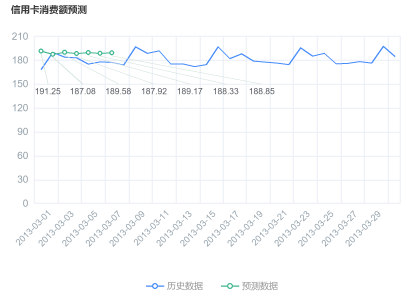

In [3]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display
import zipfile
from xml.etree import ElementTree as ET

FP=Path(r'C:\Windows\Fonts'); RS=getattr(Image,'Resampling',Image)
BASE=Path(r'C:\Users\28349\Desktop\上学期\商业数据分析\20260830 CDA教材资料2025\20260830 CDA教材资料2025\1《CDA 一级认证教材：商业数据分析》\第10章 使用效应分解方法做预报')
N='{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'

def RD(p,sh):
    z=zipfile.ZipFile(p)
    ss=[''.join(t.text or '' for t in s.iter(N+'t')) for s in ET.fromstring(z.read('xl/sharedStrings.xml'))] if 'xl/sharedStrings.xml' in z.namelist() else []
    o={}
    for c in ET.fromstring(z.read('xl/worksheets/sheet%d.xml'%sh)).iter(N+'c'):
        v=c.find(N+'v')
        if v is not None: o[c.get('r')]=ss[int(v.text)] if c.get('t')=='s' else float(v.text)
    return o

S=4
def NEW(W,H):
    im=Image.new('RGB',(W*S,H*S),'white'); return im,ImageDraw.Draw(im)
def END(im,W,H): return im.resize((W,H),RS.BOX)
def GLYP(t,z,fn,c):
    f=ImageFont.truetype(str(FP/fn),max(1,int(round(z*S))))
    tmp=Image.new('RGBA',(int((len(t)*z*1.6+100)*S),int((z*2.4+40)*S)),(0,0,0,0))
    ImageDraw.Draw(tmp).text((12*S,8*S),t,font=f,fill=(*c,255))
    return tmp.crop(tmp.getbbox())
def T(im,t,x,y,z,fn='simsun.ttc',c=(0,0,0),an='lt',rot=0):
    g=GLYP(t,z,fn,c)
    if rot: g=g.rotate(rot,expand=True,resample=RS.BICUBIC)
    w,h=g.size
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(g,(int(round(x*S-ax)),int(round(y*S-ay))),g)
def TR(im,parts,x,y,z,an='mt'):
    gs=[GLYP(t,z,fn,c) for t,fn,c in parts]
    h=max(g.height for g in gs); w=sum(g.width for g in gs)
    row=Image.new('RGBA',(w,h),(0,0,0,0)); xx=0
    for g in gs: row.paste(g,(xx,(h-g.height)//2),g); xx+=g.width
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(row,(int(round(x*S-ax)),int(round(y*S-ay))),row)
def HL(d,x0,x1,y,c,w=1): d.line([(int(x0*S),int(y*S)),(int(x1*S),int(y*S))],fill=c,width=max(1,int(round(w*S))))
def VL(d,x,y0,y1,c,w=1): d.line([(int(x*S),int(y0*S)),(int(x*S),int(y1*S))],fill=c,width=max(1,int(round(w*S))))
def LN(d,pts,c,w=2): d.line([(int(round(x*S)),int(round(y*S))) for x,y in pts],fill=c,width=max(1,int(round(w*S))),joint='curve')
def RC(d,x0,y0,x1,y1,c,w=1): d.rectangle((int(x0*S),int(y0*S),int(x1*S),int(y1*S)),outline=c,width=max(1,int(round(w*S))))
def DOT(d,x,y,r,c,w=1.5): d.ellipse((int((x-r)*S),int((y-r)*S),int((x+r)*S),int((y+r)*S)),fill=(255,255,255),outline=c,width=max(1,int(round(w*S))))

P2=BASE/'信用卡消费额_WPS自带AI功能做时间序列预测.xlsx'
if not P2.exists(): P2=Path('信用卡消费额_WPS自带AI功能做时间序列预测.xlsx')
D2=RD(P2,2); HIS2=[D2['B%d'%i] for i in range(2,33)]; PRE3=[191.25,187.08,189.58,187.92,189.17,188.33,188.85]
G=(137,137,137); BL1=(68,114,196); BL2=(91,155,213); OR=(237,125,49)
BL3=(69,139,250); GR=(64,182,140); GL=(224,230,241); GL2=(234,238,245)
def chart3():
    W,H=416,300; im,d=NEW(W,H)
    yv=lambda v:203-v/210*167
    X=lambda i:41+i*11.8
    for y in [36,60,84,108,132,156,180,203]: HL(d,34,400,y,GL2,1)
    for x in [34,58,81,105,129,152,176,200,223,246,270,293,317,341,364,388,400]: VL(d,x,36,203,GL2,1)
    for v in range(0,211,30): T(im,str(v),28,yv(v),10,'arial.ttf',(145,158,167),an='rm')
    T(im,'信用卡消费额预测',11,5,9.5,'msyhbd.ttc',(60,60,60))
    LN(d,[(X(i),yv(v)) for i,v in enumerate(HIS2)],BL3,1.2)
    LN(d,[(X(i),yv(v)) for i,v in enumerate(PRE3)],GR,1.2)
    LX=[X(i) for i in range(7)]
    for _ in range(80):
        for i in range(6):
            g=LX[i+1]-LX[i]
            if g<36: p=(36-g)/2; LX[i]-=p; LX[i+1]+=p
        LX[0]=max(LX[0],48)
    for i,v in enumerate(PRE3):
        x,y=X(i),yv(v); DOT(d,x,y,2.4,GR,1.2)
        d.line([(int(x*S),int((y+3)*S)),(int(LX[i]*S),int(84*S))],fill=(210,226,219),width=max(1,int(round(.65*S))))
        T(im,'%.2f'%v,LX[i],91,8.5,'arial.ttf',(85,90,96),an='mm')
    for k in range(15):
        T(im,'2013-03-%02d'%(1+2*k),(X(2*k)+10),210,9,'arial.ttf',(145,158,167),an='rt',rot=45)
    for x,c,t in [(155,BL3,'历史数据'),(230,GR,'预测数据')]:
        HL(d,x-9,x+9,286,c,1.2); DOT(d,x,286,2.8,c,1.2); T(im,t,x+12,286,9,'msyh.ttc',(150,150,150),an='lm')
    return END(im,W,H)
out=chart3()
out.save('信用卡消费额预测_小.png')
display(out)


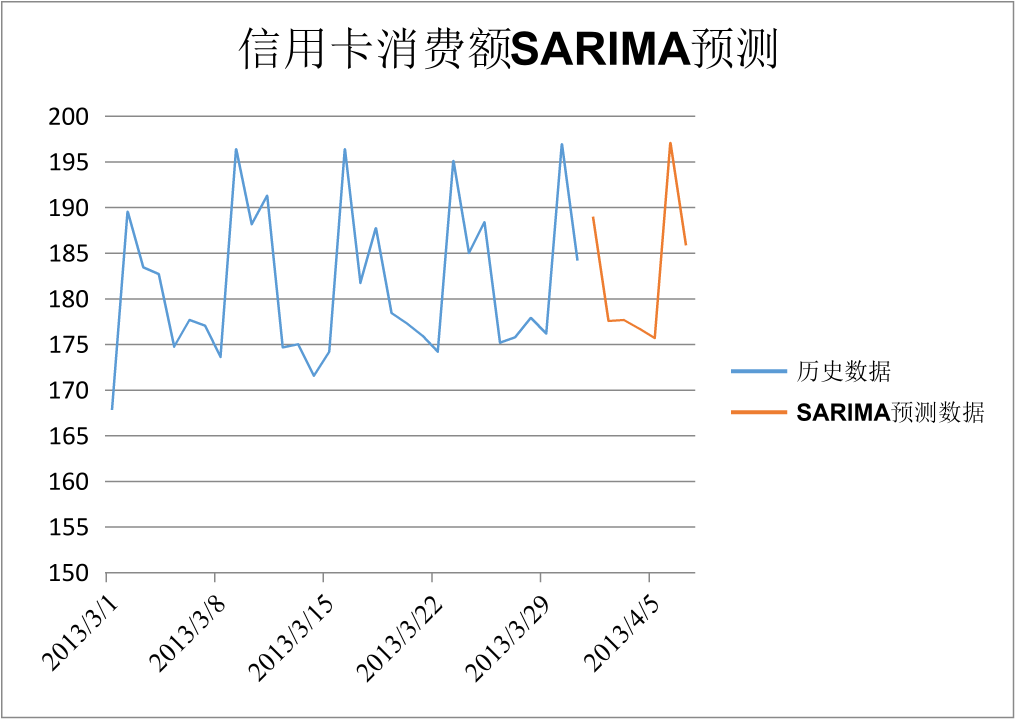

In [4]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display
import zipfile
from xml.etree import ElementTree as ET

FP=Path(r'C:\Windows\Fonts'); RS=getattr(Image,'Resampling',Image)
BASE=Path(r'C:\Users\28349\Desktop\上学期\商业数据分析\20260830 CDA教材资料2025\20260830 CDA教材资料2025\1《CDA 一级认证教材：商业数据分析》\第10章 使用效应分解方法做预报')
N='{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'

def RD(p,sh):
    z=zipfile.ZipFile(p)
    ss=[''.join(t.text or '' for t in s.iter(N+'t')) for s in ET.fromstring(z.read('xl/sharedStrings.xml'))] if 'xl/sharedStrings.xml' in z.namelist() else []
    o={}
    for c in ET.fromstring(z.read('xl/worksheets/sheet%d.xml'%sh)).iter(N+'c'):
        v=c.find(N+'v')
        if v is not None: o[c.get('r')]=ss[int(v.text)] if c.get('t')=='s' else float(v.text)
    return o

S=4
def NEW(W,H):
    im=Image.new('RGB',(W*S,H*S),'white'); return im,ImageDraw.Draw(im)
def END(im,W,H): return im.resize((W,H),RS.BOX)
def GLYP(t,z,fn,c):
    f=ImageFont.truetype(str(FP/fn),max(1,int(round(z*S))))
    tmp=Image.new('RGBA',(int((len(t)*z*1.6+100)*S),int((z*2.4+40)*S)),(0,0,0,0))
    ImageDraw.Draw(tmp).text((12*S,8*S),t,font=f,fill=(*c,255))
    return tmp.crop(tmp.getbbox())
def T(im,t,x,y,z,fn='simsun.ttc',c=(0,0,0),an='lt',rot=0):
    g=GLYP(t,z,fn,c)
    if rot: g=g.rotate(rot,expand=True,resample=RS.BICUBIC)
    w,h=g.size
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(g,(int(round(x*S-ax)),int(round(y*S-ay))),g)
def TR(im,parts,x,y,z,an='mt'):
    gs=[GLYP(t,z,fn,c) for t,fn,c in parts]
    h=max(g.height for g in gs); w=sum(g.width for g in gs)
    row=Image.new('RGBA',(w,h),(0,0,0,0)); xx=0
    for g in gs: row.paste(g,(xx,(h-g.height)//2),g); xx+=g.width
    ax={'l':0,'m':w/2,'r':w}[an[0]]; ay={'t':0,'m':h/2,'b':h}[an[1]]
    im.paste(row,(int(round(x*S-ax)),int(round(y*S-ay))),row)
def HL(d,x0,x1,y,c,w=1): d.line([(int(x0*S),int(y*S)),(int(x1*S),int(y*S))],fill=c,width=max(1,int(round(w*S))))
def VL(d,x,y0,y1,c,w=1): d.line([(int(x*S),int(y0*S)),(int(x*S),int(y1*S))],fill=c,width=max(1,int(round(w*S))))
def LN(d,pts,c,w=2): d.line([(int(round(x*S)),int(round(y*S))) for x,y in pts],fill=c,width=max(1,int(round(w*S))),joint='curve')
def RC(d,x0,y0,x1,y1,c,w=1): d.rectangle((int(x0*S),int(y0*S),int(x1*S),int(y1*S)),outline=c,width=max(1,int(round(w*S))))
def DOT(d,x,y,r,c,w=1.5): d.ellipse((int((x-r)*S),int((y-r)*S),int((x+r)*S),int((y+r)*S)),fill=(255,255,255),outline=c,width=max(1,int(round(w*S))))

P2=BASE/'信用卡消费额_WPS自带AI功能做时间序列预测.xlsx'
if not P2.exists(): P2=Path('信用卡消费额_WPS自带AI功能做时间序列预测.xlsx')
D2=RD(P2,2); HIS2=[D2['B%d'%i] for i in range(2,33)]; PRE2=[D2['C%d'%i] for i in range(33,40)]
G=(137,137,137); BL1=(68,114,196); BL2=(91,155,213); OR=(237,125,49)
BL3=(69,139,250); GR=(64,182,140); GL=(224,230,241); GL2=(234,238,245)
def chart4():
    W,H=1016,720; im,d=NEW(W,H)
    yv=lambda v:572.6-(v-150)/50*456.4
    X=lambda i:112+i*15.51
    for v in range(150,201,5): HL(d,105,695,yv(v),G,1.5)
    for v in range(150,201,5): T(im,str(v),88,yv(v),27,'calibri.ttf',an='rm')
    for k in range(6): VL(d,106+108.6*k,573,582,G,1.5)
    TR(im,[('信用卡消费额','simsun.ttc',(0,0,0)),('SARIMA','arialbd.ttf',(0,0,0)),('预测','simsun.ttc',(0,0,0))],W/2,27,46,an='mt')
    LN(d,[(X(i),yv(v)) for i,v in enumerate(HIS2)],BL2,2.5)
    LN(d,[(X(31+i),yv(v)) for i,v in enumerate(PRE2)],OR,2.5)
    labs=['2013/3/1','2013/3/8','2013/3/15','2013/3/22','2013/3/29','2013/4/5']
    for k,t in enumerate(labs): T(im,t,118+108.6*k,593,27,'times.ttf',an='rt',rot=45)
    HL(d,731,787,371,BL2,4); T(im,'历史数据',797,371,24,an='lm')
    HL(d,731,787,412,OR,4)
    TR(im,[('SARIMA','arialbd.ttf',(0,0,0)),('预测数据','simsun.ttc',(0,0,0))],797,412,24,an='lm')
    RC(d,1,1,W-2,H-2,G,1.5)
    return END(im,W,H)
out=chart4()
out.save('信用卡消费额SARIMA预测.png')
display(out)
